In [1]:
import os

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

plt.rcParams["font.sans-serif"] = ["SimHei"]      # Windows
plt.rcParams["axes.unicode_minus"] = False        # 让负号正常显示

In [2]:
# 设置基本参数
DATA_PATH = "data/ecommerce_events.csv"

# 清洗后的数据、特征宽表、中间结果等统一放到该文件夹下
OUTPUT_DIR = "data/processed"
# 清洗后分块数据的子目录
CLEAN_PART_DIR = os.path.join(OUTPUT_DIR, "clean_parts")

# 创建目录
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(CLEAN_PART_DIR, exist_ok=True)

# 设置分块大小
CHUNK_SIZE = 500_000

In [3]:
# 设置数据类型

USE_COLS = [
    "event_time",
    "event_type",
    "product_id",
    "category_id",
    "category_code",
    "brand",
    "price",
    "user_id",
    "user_session"
]

# 指定每列的数据类型
DTYPE = {
    "event_type": "string",
    "product_id": "string",
    "category_id": "string",
    "category_code": "string",
    "brand": "string",
    "price": "float32",
    "user_id": "string",
    "user_session": "string"
}

In [5]:
# 获取数据时间范围

def get_time_range(file_path):
    min_time = None
    max_time = None
    
#     分块读取
    for chunk in pd.read_csv(
        file_path,
        usecols=["event_time"],
        chunksize=CHUNK_SIZE
    ):
        
#         解析时间并去掉空值
        current_time = pd.to_datetime(
            chunk["event_time"],
            errors="coerce"
        ).dropna()

        if current_time.empty:
            continue

        chunk_min = current_time.min()
        chunk_max = current_time.max()

#         更新全局最小值/最大值
        if min_time is None or chunk_min < min_time:
            min_time = chunk_min

        if max_time is None or chunk_max > max_time:
            max_time = chunk_max

    return min_time, max_time

data_min_time, data_max_time = get_time_range(DATA_PATH)

print("数据开始时间：", data_min_time)
print("数据结束时间：", data_max_time)

数据开始时间： 2019-10-01 00:00:00
数据结束时间： 2019-10-31 23:59:58


### 定义观察窗口和预测窗口
观察窗口：用于构造用户特征；
预测窗口：用于构造用户是否购买的标签

In [6]:
# 设置预测窗口长度
PREDICT_DAYS = 3

# 计算观察窗口的结束时间
observation_end = (
    data_max_time.normalize()
    - pd.Timedelta(days=PREDICT_DAYS)
)

# 计算预测窗口的结束时间
prediction_end = (
    data_max_time
    + pd.Timedelta(seconds=1)
)

print("观察窗口结束时间：", observation_end)
print("预测窗口结束时间：", prediction_end)

观察窗口结束时间： 2019-10-28 00:00:00
预测窗口结束时间： 2019-10-31 23:59:59


In [7]:
# 整个数据块的清洗函数

def clean_chunk(chunk):
    # 去除字段名首尾空格
    chunk.columns = [
        col.strip().lower()
        for col in chunk.columns
    ]

    # 时间字段处理
    chunk["event_time"] = pd.to_datetime(
        chunk["event_time"],
        errors="coerce"
    )

    # 删除关键字段为空的数据
    required_cols = [
        "event_time",
        "event_type",
        "product_id",
        "category_id",
        "user_id"
    ]

    chunk = chunk.dropna(subset=required_cols)

    # 行为字段标准化
    chunk["event_type"] = (
        chunk["event_type"]
        .astype("string")
        .str.strip()
        .str.lower()
    )

    # 兼容不同数据集的行为命名
    behavior_mapping = {
        "buy": "purchase",
        "pv": "view",
        "add_to_cart": "cart",
        "remove": "remove_from_cart"
    }

    chunk["event_type"] = (
        chunk["event_type"]
        .replace(behavior_mapping)
    )

    valid_events = [
        "view",
        "cart",
        "remove_from_cart",
        "purchase"
    ]

    chunk = chunk[
        chunk["event_type"].isin(valid_events)
    ]

    # 价格异常值处理
    chunk["price"] = pd.to_numeric(
        chunk["price"],
        errors="coerce"
    )

    chunk.loc[
        chunk["price"] < 0,
        "price"
    ] = np.nan

    # 缺失类别和品牌统一填充
    chunk["category_code"] = (
        chunk["category_code"]
        .fillna("unknown")
        .astype("string")
    )

    chunk["brand"] = (
        chunk["brand"]
        .fillna("unknown")
        .astype("string")
    )

    # 删除异常时间
    chunk = chunk[
        chunk["event_time"].notna()
    ]

    # 衍生时间字段
    chunk["date"] = chunk["event_time"].dt.date
    chunk["hour"] = chunk["event_time"].dt.hour
    chunk["weekday"] = chunk["event_time"].dt.weekday

    return chunk

In [8]:
# 分块清洗并保存 Parquet

def clean_to_parquet():
#     分块读取CSV
    for part_id, chunk in enumerate(
        pd.read_csv(
            DATA_PATH,
            usecols=USE_COLS,
            dtype=DTYPE,
            chunksize=CHUNK_SIZE
        )
    ):
        print(f"正在清洗第 {part_id + 1} 个数据块")

        clean_part = clean_chunk(chunk)
        
#         跳过空块
        if clean_part.empty:
            continue
#         生成输出路径
        output_path = os.path.join(
            CLEAN_PART_DIR,
            f"part_{part_id:04d}.parquet"
        )
#         把清洗后的块保存成 Parquet 文件
        clean_part.to_parquet(
            output_path,
            index=False
        )

        print(
            f"保存：{output_path}，"
            f"数据量：{len(clean_part)}"
        )


In [9]:
# 执行
clean_to_parquet()

正在清洗第 1 个数据块
保存：data/processed\clean_parts\part_0000.parquet，数据量：500000
正在清洗第 2 个数据块
保存：data/processed\clean_parts\part_0001.parquet，数据量：500000
正在清洗第 3 个数据块
保存：data/processed\clean_parts\part_0002.parquet，数据量：500000
正在清洗第 4 个数据块
保存：data/processed\clean_parts\part_0003.parquet，数据量：500000
正在清洗第 5 个数据块
保存：data/processed\clean_parts\part_0004.parquet，数据量：500000
正在清洗第 6 个数据块
保存：data/processed\clean_parts\part_0005.parquet，数据量：500000
正在清洗第 7 个数据块
保存：data/processed\clean_parts\part_0006.parquet，数据量：500000
正在清洗第 8 个数据块
保存：data/processed\clean_parts\part_0007.parquet，数据量：500000
正在清洗第 9 个数据块
保存：data/processed\clean_parts\part_0008.parquet，数据量：500000
正在清洗第 10 个数据块
保存：data/processed\clean_parts\part_0009.parquet，数据量：500000
正在清洗第 11 个数据块
保存：data/processed\clean_parts\part_0010.parquet，数据量：500000
正在清洗第 12 个数据块
保存：data/processed\clean_parts\part_0011.parquet，数据量：500000
正在清洗第 13 个数据块
保存：data/processed\clean_parts\part_0012.parquet，数据量：500000
正在清洗第 14 个数据块
保存：data/processed\clean_parts\part_0013.parque

In [9]:
# 初始化容器

user_stat_parts = []       # 分块存 用户行为统计
active_day_parts = []      # 分块存 用户活跃天数
hourly_parts = []          # 分块存 用户活跃小时分布
product_parts = []         # 分块存 用户-商品交互
category_parts = []        # 分块存 用户-品类交互

# 收集未来会购买的用户
future_purchase_users = set()

In [11]:
# 分块读取和聚合

for part_id, chunk in enumerate(
    pd.read_csv(
        DATA_PATH,
        usecols=USE_COLS,
        dtype=DTYPE,
        chunksize=CHUNK_SIZE
    )
):
    print(f"正在处理第 {part_id + 1} 个数据块")

    chunk = clean_chunk(chunk)

    if chunk.empty:
        continue

    # 划分观察窗口和预测窗口
    history = chunk[
        chunk["event_time"] < observation_end
    ].copy()

    future = chunk[
        (chunk["event_time"] >= observation_end) &
        (chunk["event_time"] < prediction_end)
    ].copy()

    # 统计预测窗口内购买用户
    future_purchase_users.update(
        future.loc[
            future["event_type"] == "purchase",
            "user_id"
        ].dropna().unique()
    )

    if history.empty:
        continue

    # --------------------------------------------------
    # 1. 用户行为次数
    # --------------------------------------------------
    event_count_part = (
        history
        .groupby(["user_id", "event_type"])
        .size()
        .unstack(fill_value=0)
    )

    expected_events = [
        "view",
        "cart",
        "remove_from_cart",
        "purchase"
    ]

    event_count_part = event_count_part.reindex(
        columns=expected_events,
        fill_value=0
    )

    event_count_part = event_count_part.rename(
        columns={
            "view": "view_count",
            "cart": "cart_count",
            "remove_from_cart": "remove_cart_count",
            "purchase": "purchase_count"
        }
    )

    event_count_part["event_count"] = (
        event_count_part.sum(axis=1)
    )

    # --------------------------------------------------
    # 2. 用户其他统计特征
    # --------------------------------------------------
    user_stat_part = (
        history
        .groupby("user_id")
        .agg(
            price_sum=("price", "sum"),
            price_count=("price", "count"),
            price_max=("price", "max"),
            hour_sum=("hour", "sum"),
            first_event_time=("event_time", "min"),
            last_event_time=("event_time", "max")
        )
    )

    user_stat_part = user_stat_part.join(
        event_count_part,
        how="outer"
    )

    user_stat_part = user_stat_part.reset_index()

    user_stat_parts.append(user_stat_part)

    # --------------------------------------------------
    # 3. 用户活跃天数
    # --------------------------------------------------
    active_day_part = (
        history[["user_id", "date"]]
        .drop_duplicates()
    )

    active_day_parts.append(active_day_part)

    # --------------------------------------------------
    # 4. 小时行为分布
    # --------------------------------------------------
    hourly_part = (
        history
        .groupby(["hour", "event_type"])
        .size()
        .reset_index(name="event_count")
    )

    hourly_parts.append(hourly_part)

    # --------------------------------------------------
    # 5. 商品热度
    # --------------------------------------------------
    product_part = (
        history
        .groupby(["product_id", "event_type"])
        .size()
        .reset_index(name="event_count")
    )

    product_parts.append(product_part)

    # --------------------------------------------------
    # 6. 类目热度
    # --------------------------------------------------
    category_part = (
        history
        .groupby(["category_id", "event_type"])
        .size()
        .reset_index(name="event_count")
    )

    category_parts.append(category_part)

正在处理第 1 个数据块
正在处理第 2 个数据块
正在处理第 3 个数据块
正在处理第 4 个数据块
正在处理第 5 个数据块
正在处理第 6 个数据块
正在处理第 7 个数据块
正在处理第 8 个数据块
正在处理第 9 个数据块
正在处理第 10 个数据块
正在处理第 11 个数据块
正在处理第 12 个数据块
正在处理第 13 个数据块
正在处理第 14 个数据块
正在处理第 15 个数据块
正在处理第 16 个数据块
正在处理第 17 个数据块
正在处理第 18 个数据块
正在处理第 19 个数据块


In [12]:
# 合并用户统计
user_stat_all = pd.concat(
    user_stat_parts,
    ignore_index=True
)

In [13]:
# 需要求和的字段
sum_cols = [
    "price_sum",
    "price_count",
    "hour_sum",
    "view_count",
    "cart_count",
    "remove_cart_count",
    "purchase_count",
    "event_count"
]

In [14]:
# 对于时间字段和最大价格
# 把多块合并后的用户统计表，按user_id做最终聚合，生成每个用户一行的“用户特征宽表”
user_features = (
    user_stat_all
    .groupby("user_id")
    .agg(
        price_sum=("price_sum", "sum"),
        price_count=("price_count", "sum"),
        price_max=("price_max", "max"),
        hour_sum=("hour_sum", "sum"),
        first_event_time=("first_event_time", "min"),
        last_event_time=("last_event_time", "max"),
        view_count=("view_count", "sum"),
        cart_count=("cart_count", "sum"),
        remove_cart_count=("remove_cart_count", "sum"),
        purchase_count=("purchase_count", "sum"),
        event_count=("event_count", "sum")
    )
    .reset_index()
)

In [15]:
# 合并所有块
active_day_all = pd.concat(
    active_day_parts,
    ignore_index=True
)
# 去重
active_day_all = (
    active_day_all
    .drop_duplicates()
)
# 按用户统计
active_days = (
    active_day_all
    .groupby("user_id")
    .size()
    .reset_index(name="active_days")
)
# 把活跃天数这一列拼接到用户特征宽表里
user_features = user_features.merge(
    active_days,
    on="user_id",
    how="left"
)

In [16]:
# 计算价格特征
user_features["avg_price"] = (
    user_features["price_sum"] /
    user_features["price_count"].replace(0, np.nan)
)

user_features["avg_price"] = (
    user_features["avg_price"].fillna(0)
)

In [17]:
# 计算用户平均活跃小时
user_features["avg_active_hour"] = (
    user_features["hour_sum"] /
    user_features["event_count"].replace(0, np.nan)
)

user_features["avg_active_hour"] = (
    user_features["avg_active_hour"].fillna(0)
)

In [18]:
# 计算最近行为时间

# 得到观察期最后一秒对应的时间
history_max_time = (
    observation_end - pd.Timedelta(seconds=1)
)

# 用观察期最后时刻 - 用户最后一次行为时间，得到时间差，再将其换算成小时
user_features["recency_hours"] = (
    history_max_time -
    user_features["last_event_time"]
).dt.total_seconds() / 3600

# 将小于0的值全部改为0
user_features["recency_hours"] = (
    user_features["recency_hours"]
    .clip(lower=0)
)

In [19]:
# 预测窗口内购买过的用户
label_df = pd.DataFrame({
    "user_id": list(future_purchase_users),
    "target": 1
})

# 和所有历史用户合并
user_features = user_features.merge(
    label_df,
    on="user_id",
    how="left"
)

user_features["target"] = (
    user_features["target"]
    .fillna(0)
    .astype(int)
)

### 标签定义：
target = 1：用户在预测窗口内购买；
target = 0：用户在预测窗口内没有购买


In [20]:
# 检查标签比例
print(user_features["target"].value_counts())
print(user_features["target"].value_counts(normalize=True))

0    2749971
1      20688
Name: target, dtype: int64
0    0.992533
1    0.007467
Name: target, dtype: float64


In [21]:
# 构造比例特征

# 加购率，计算用户“加购次数/浏览次数”
user_features["cart_rate"] = (
    user_features["cart_count"] /
    user_features["view_count"].replace(0, np.nan)
)
# 购买率
user_features["purchase_rate"] = (
    user_features["purchase_count"] /
    user_features["view_count"].replace(0, np.nan)
)
# 移除购物车率
user_features["remove_cart_rate"] = (
    user_features["remove_cart_count"] /
    user_features["cart_count"].replace(0, np.nan)
)
# 把整张表里的正负无穷大 inf、-inf 替换成 NaN
user_features = user_features.replace(
    [np.inf, -np.inf],
    np.nan
)

user_features = user_features.fillna(0)

In [23]:
# 保存用户特征
feature_path = os.path.join(
    OUTPUT_DIR,
    "user_features.csv"
)

user_features.to_csv(
    feature_path,
    index=False,
    encoding="utf-8-sig"
)

print("用户特征已保存：", feature_path)

用户特征已保存： data/processed\user_features.csv


In [22]:
# 生成小时行为分析数据
hourly_all = pd.concat(
    hourly_parts,
    ignore_index=True
)

hourly_behavior = (
    hourly_all
    .groupby(["hour", "event_type"])["event_count"]
    .sum()
    .reset_index()
)

hourly_behavior.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "hourly_behavior.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

print(hourly_behavior.head())

   hour event_type  event_count
0     0       cart          396
1     0   purchase          786
2     0       view        59491
3     1       cart          863
4     1   purchase         1779


In [23]:
# 生成商品热度分析数据

product_all = pd.concat(
    product_parts,
    ignore_index=True
)

product_analysis = (
    product_all
    .groupby(["product_id", "event_type"])["event_count"]
    .sum()
    .unstack(fill_value=0)
    .reset_index()
)

# 确保字段存在：
for col in [
    "view",
    "cart",
    "remove_from_cart",
    "purchase"
]:
    if col not in product_analysis.columns:
        product_analysis[col] = 0
        
# 重命名：
product_analysis = product_analysis.rename(
    columns={
        "view": "view_count",
        "cart": "cart_count",
        "remove_from_cart": "remove_cart_count",
        "purchase": "purchase_count"
    }
)

# 计算商品转化率：
product_analysis["conversion_rate"] = (
    product_analysis["purchase_count"] /
    product_analysis["view_count"].replace(0, np.nan)
)

product_analysis["conversion_rate"] = (
    product_analysis["conversion_rate"]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

# 为了避免浏览量太少的商品导致转化率虚高：
product_analysis_filtered = product_analysis[
    product_analysis["view_count"] >= 50
].copy()

In [24]:
# 按浏览量排序：
top_view_products = (
    product_analysis
    .sort_values("view_count", ascending=False)
    .head()
)

print(top_view_products)

event_type product_id  cart_count  purchase_count  view_count  \
906           1004856        4633            9910      111135   
830           1004767        3264            6947      105235   
1106          1005115        1750            2751       80960   
116872        4804056        3458            4419       57236   
1096          1005105        1282            1533       56820   

event_type  remove_cart_count  conversion_rate  
906                         0         0.089171  
830                         0         0.066014  
1106                        0         0.033980  
116872                      0         0.077207  
1096                        0         0.026980  


In [25]:
# 按购买量排序：
top_purchase_products = (
    product_analysis
    .sort_values("purchase_count", ascending=False)
    .head()
)

print(top_purchase_products)

event_type product_id  cart_count  purchase_count  view_count  \
906           1004856        4633            9910      111135   
830           1004767        3264            6947      105235   
116872        4804056        3458            4419       57236   
885           1004833        1686            4177       50479   
916           1004870        1713            3412       44441   

event_type  remove_cart_count  conversion_rate  
906                         0         0.089171  
830                         0         0.066014  
116872                      0         0.077207  
885                         0         0.082747  
916                         0         0.076776  


In [26]:
# 保存：
product_analysis.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "product_analysis.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

In [27]:
# 生成类目分析数据
category_all = pd.concat(
    category_parts,
    ignore_index=True
)

category_analysis = (
    category_all
    .groupby(["category_id", "event_type"])["event_count"]
    .sum()
    .unstack(fill_value=0)
    .reset_index()
)

for col in [
    "view",
    "cart",
    "remove_from_cart",
    "purchase"
]:
    if col not in category_analysis.columns:
        category_analysis[col] = 0

category_analysis = category_analysis.rename(
    columns={
        "view": "view_count",
        "cart": "cart_count",
        "remove_from_cart": "remove_cart_count",
        "purchase": "purchase_count"
    }
)
# 计算转化率
category_analysis["conversion_rate"] = (
    category_analysis["purchase_count"] /
    category_analysis["view_count"].replace(0, np.nan)
)

category_analysis = category_analysis.fillna(0)
# 导出CSV
category_analysis.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "category_analysis.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

### 转化漏斗

浏览用户数  →  加购用户数  →  购买用户数

In [28]:
# 用户转化漏斗
behavior_users = {
    "view": set(),
    "cart": set(),
    "remove_from_cart": set(),
    "purchase": set()
}

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=["event_type", "user_id"],
    dtype={
        "event_type": "string",
        "user_id": "string"
    },
    chunksize=CHUNK_SIZE
):
    
#     把 event_type 列标准化
    chunk["event_type"] = (
        chunk["event_type"]
        .astype("string")
        .str.lower()
        .str.strip()
        .replace({
            "buy": "purchase",
            "pv": "view",
            "add_to_cart": "cart",
            "remove": "remove_from_cart"
        })
    )
    
#     统计每种行为对应的用户集合
    for event_name in behavior_users.keys():
        current_users = chunk.loc[
            chunk["event_type"] == event_name,
            "user_id"
        ].dropna().unique()

        behavior_users[event_name].update(
            current_users
        )

In [29]:
# 生成漏斗

# 构造漏斗 DataFrame
funnel = pd.DataFrame({
    "behavior": [
        "view",
        "cart",
        "purchase"
    ],
    "user_count": [
        len(behavior_users["view"]),
        len(behavior_users["cart"]),
        len(behavior_users["purchase"])
    ]
})

# 计算相对浏览用户的转化率
funnel["conversion_rate_from_view"] = (
    funnel["user_count"] /
    funnel.loc[0, "user_count"]
)

print(funnel)

funnel.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "funnel.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

   behavior  user_count  conversion_rate_from_view
0      view     2984091                   1.000000
1      cart       80721                   0.027050
2  purchase      208670                   0.069927


In [10]:
from sklearn.model_selection import train_test_split

In [11]:
# 模型训练
# 1. 准备特征

model_df = user_features.copy()

# 定义要丢弃的列
drop_columns = [
    "user_id",
    "first_event_time",
    "last_event_time",
    "target"
]

# 构造特征矩阵 X
X = model_df.drop(
    columns=drop_columns,
    errors="ignore"
)
# 构造标签 y
y = model_df["target"]

In [12]:
# 检查数据：

print(X.shape)
print(X.dtypes)
print(y.value_counts())

(2770659, 16)
price_sum            float32
price_count            int64
price_max            float32
hour_sum               int64
view_count             int64
cart_count             int64
remove_cart_count      int64
purchase_count         int64
event_count            int64
active_days            int64
avg_price            float32
avg_active_hour      float64
recency_hours        float64
cart_rate            float64
purchase_rate        float64
remove_cart_rate     float64
dtype: object
0    2749971
1      20688
Name: target, dtype: int64


In [13]:
# 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [15]:
# 逻辑回归

lr_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# 训练模型
lr_model.fit(X_train, y_train)

# 预测类别
lr_pred = lr_model.predict(X_test)
# 预测概率
lr_prob = lr_model.predict_proba(X_test)[:, 1]

In [18]:
#  随机森林

rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

In [19]:
# 模型评估

# 导入评估指标
from sklearn.metrics import (
    accuracy_score,             # 准确率
    precision_score,            # 精确率
    recall_score,               # 召回率
    f1_score,                   # 精确率和召回率的调和平均
    roc_auc_score,              # 综合排序能力
    average_precision_score,    # 不平衡数据下比AUC更敏感
    classification_report,      # 分类报告：一次性显示precision/recall/f1
    confusion_matrix            # 看 TP/FP/FN/TN 分布
)

# 定义评估函数
def evaluate_model(
    model_name,
    y_true,
    y_pred,
    y_prob
):
    result = {
        "model": model_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "recall": recall_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "f1": f1_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "roc_auc": roc_auc_score(
            y_true,
            y_prob
        ),
        "pr_auc": average_precision_score(
            y_true,
            y_prob
        )
    }

    print(f"\n模型：{model_name}")
    print(pd.Series(result))

    print("\n分类报告：")
    print(classification_report(
        y_true,
        y_pred,
        zero_division=0
    ))

    print("混淆矩阵：")
    print(confusion_matrix(y_true, y_pred))

    return result

lr_result = evaluate_model(
    "Logistic Regression",
    y_test,
    lr_pred,
    lr_prob
)

# 评估两个模型
rf_result = evaluate_model(
    "Random Forest",
    y_test,
    rf_pred,
    rf_prob
)

model_result = pd.DataFrame([
    lr_result,
    rf_result
])

model_result.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "model_result.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)


模型：Logistic Regression
model        Logistic Regression
accuracy                0.792512
precision               0.022793
recall                  0.639681
f1                     0.0440176
roc_auc                 0.778184
pr_auc                 0.0608296
dtype: object

分类报告：
              precision    recall  f1-score   support

           0       1.00      0.79      0.88    549994
           1       0.02      0.64      0.04      4138

    accuracy                           0.79    554132
   macro avg       0.51      0.72      0.46    554132
weighted avg       0.99      0.79      0.88    554132

混淆矩阵：
[[436509 113485]
 [  1491   2647]]

模型：Random Forest
model        Random Forest
accuracy          0.823024
precision        0.0246939
recall            0.589657
f1               0.0474026
roc_auc           0.779513
pr_auc           0.0582238
dtype: object

分类报告：
              precision    recall  f1-score   support

           0       1.00      0.82      0.90    549994
           1       

In [20]:
# 随机森林特征重要性

rf_estimator = rf_model.named_steps["model"]
# 构造特征重要性
feature_importance = pd.DataFrame({
    "feature": X.columns,
    "importance": rf_estimator.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

print(feature_importance.head(20))

              feature  importance
9         active_days    0.172018
12      recency_hours    0.168193
8         event_count    0.133172
1         price_count    0.093817
7      purchase_count    0.080646
4          view_count    0.076330
3            hour_sum    0.060476
14      purchase_rate    0.059127
0           price_sum    0.044120
2           price_max    0.036436
10          avg_price    0.035823
11    avg_active_hour    0.028327
5          cart_count    0.006209
13          cart_rate    0.005305
6   remove_cart_count    0.000000
15   remove_cart_rate    0.000000


<Figure size 720x432 with 0 Axes>

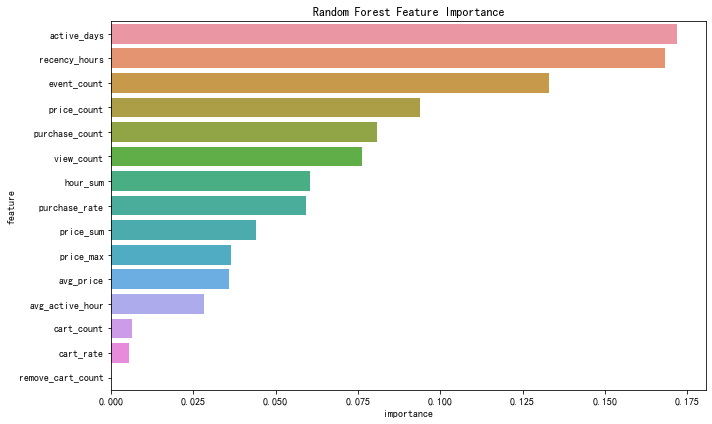

In [22]:
# 可视化：

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(15),
    x="importance",
    y="feature"
)

plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

In [23]:
# 生成高潜用户名单
prediction_result = pd.DataFrame({
    "user_id": model_df.loc[
        X_test.index,
        "user_id"
    ],
    "actual_target": y_test,
    "predict_target": rf_pred,
    "purchase_probability": rf_prob
})

prediction_result = prediction_result.sort_values(
    "purchase_probability",
    ascending=False
)

prediction_result.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "user_purchase_prediction.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

In [24]:
# 筛选高潜用户：
high_potential_users = prediction_result[
    prediction_result["purchase_probability"] >= 0.7
]

print(high_potential_users.head(20))


           user_id  actual_target  predict_target  purchase_probability
64659    512684227              1               1              0.990538
895326   525690046              1               1              0.987216
1705221  551882599              1               1              0.986030
1525809  547189232              1               1              0.985806
735827   521089088              1               1              0.984871
885348   525351013              1               1              0.983124
1647534  550332167              0               1              0.982612
1978152  556757311              0               1              0.980960
552264   517857007              0               1              0.980914
212096   513817018              0               1              0.980768
289270   514597168              1               1              0.980708
1035316  531261934              0               1              0.980222
1395853  543595420              1               1              0